In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [9]:
PATH = '/home/sssclass/Desktop/project/cs229/problem_set1/ps1'
OUTPUT_PATH ='/home/sssclass/Desktop/project/cs229/problem_set1/output' 
e = 10 ** -5

In [12]:
train_data = pd.read_csv(f'{PATH}/ds1_train.csv')
validation_data = pd.read_csv(f'{PATH}/ds1_valid.csv')
train_data.insert(2, 'b', 1.0)               
validation_data.insert(2, 'b', 1.0)               


In [13]:
features = ['x_1', 'x_2', 'b']

In [14]:
def sigmoid(X, theta):
    return 1 / (1 + np.exp(-X.dot(theta)))


In [15]:
def building_Hessian(X, theta):
    h = 1 / (1 + np.exp(-X.dot(theta)))
    s = h * (1 - h)                    
    return -(X.mul(s, axis=0).T).dot(X)   

    
def calculate_gradient(X, y, theta):
    h =  sigmoid(X, theta)
    return X.T.dot(y - h)    
    



In [16]:
def newton_optimizer():
    X = train_data[features]
    y = train_data['y']
    theta = np.zeros(3)

    while True:
        g = calculate_gradient(X, y, theta).values
        H = building_Hessian(X, theta).values

        old_theta = theta
        theta = old_theta - np.linalg.solve(H, g)

        if np.abs(theta - old_theta).sum() < e:
            break

    return theta

In [40]:
def ouput_validation(theta):
    y_hat = sigmoid(validation_data[features],theta)
    y_hat.to_csv(f'{OUTPUT_PATH}/predict', index=False, header=False)



def plot(theta):

    fig, ax = plt.subplots(figsize=(12, 5))
    class0 = validation_data[validation_data['y'] == 0]
    class1 = validation_data[validation_data['y'] == 1]

    ax.scatter(class0['x_1'],class0['x_2'], marker='o', label='y=0')
    ax.scatter(class1['x_1'], class1['x_2'], marker='x', label='y=1')

    xs = np.array([validation_data['x_1'].min(), validation_data['x_1'].max()])
    ys = -(theta[0]*xs + theta[2]) / theta[1]
    ax.plot(xs, ys, 'k-', label='boundary')
    
    ax.set_xlabel('x1')
    ax.set_ylabel('x2')
    ax.set_title('logistic prediction')
    ax.legend()
    fig.savefig(f'{OUTPUT_PATH}/plots.png')
    plt.show()

In [41]:
def main():
    theta = newton_optimizer()
    ouput_validation(theta)
    plot(theta)


    print(theta)

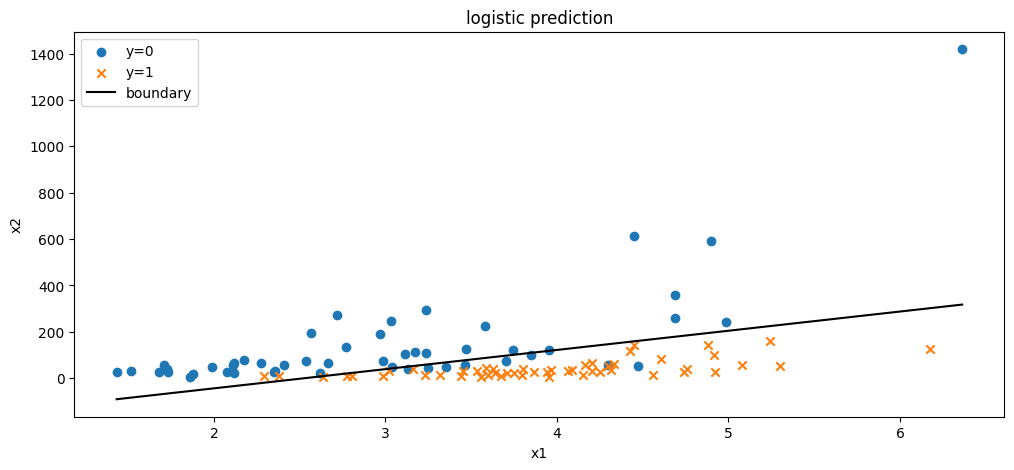

[ 2.47707251 -0.0299125  -6.26018491]


In [42]:
main()

(2,)


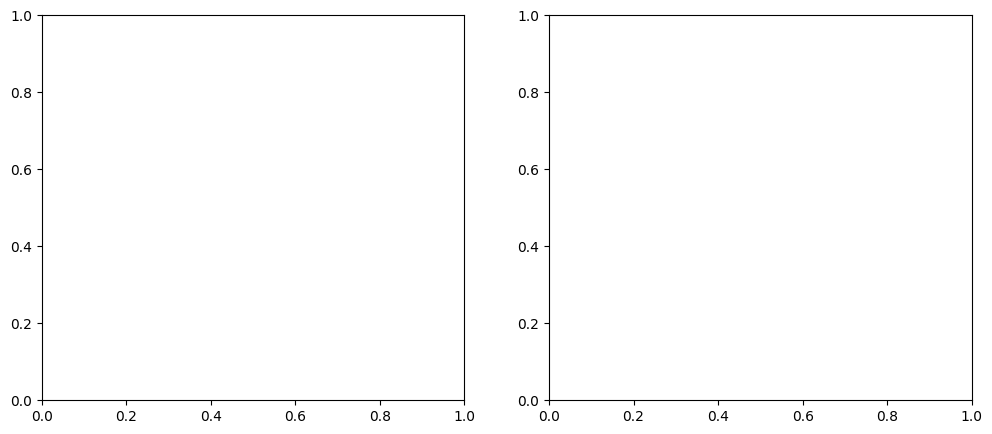

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
